# Classificação de Espécies de Corujas com CNN Própria

## Apresentação única — V1 como base, V2–V5 como melhorias e MobileNetV2 como ramo experimental

Este notebook é a **única apresentação do projeto**. Ele reúne a versão base, a evolução da CNN própria e o teste derivado com MobileNetV2.

- **V1 — versão base:** primeira CNN, com `Flatten` e 12,94M de parâmetros.
- **V2 a V5 — melhorias da CNN própria:** ajustes de arquitetura, pesos, divisão dos dados e seleção de modelo.
- **MobileNetV2 — ramo experimental da V2:** não é uma nova versão da CNN própria. É um teste de teto para medir o ganho possível com transfer learning.

**Resumo dos resultados disponíveis:**

| Versão | Acurácia | F1 macro | Classes com recall zero | Protocolo |
|---|---:|---:|---:|---|
| V1 | 62,49% | 9,55% | 14 | Validação 80/20 |
| V2 | 60,03% | 12,66% | 12 | Teste 70/15/15 |
| V3 | 31,46% | 11,74% | 6 | Teste 70/15/15 |
| **V4** | **58,63%** | **22,82%** | **3** | **Teste 70/15/15** |
| V5 | 58,55% | 17,08% | 8 | Teste 70/15/15 |

A V4 é a melhor versão oficial da CNN própria. O ramo MobileNetV2 será apresentado apenas no tópico 8.

> Este notebook não treina modelos. Ele usa os resultados já registrados para apresentar a análise, os gráficos e as comparações.


## Sumário

1. Introdução, base de dados e tecnologias
2. Metodologia e evolução dos experimentos
3. Base técnica da V4
4. Resultados da V4
5. Comparação V1, V2, V3, V4 e V5
6. Por que a V4 foi a melhor
7. Problemas enfrentados, soluções e limitações
8. Ramo experimental da V2: MobileNetV2 como teto
9. Conclusão e aplicações em Engenharia


# 1. Introdução, base de dados e tecnologias

## Contexto

A identificação visual de aves é uma tarefa de **classificação multiclasse** em Visão Computacional. Espécies de corujas podem ser visualmente semelhantes, com diferenças de plumagem, formato facial, bico e padrões de olhos. Automatizar essa identificação pode apoiar o **monitoramento não intrusivo da biodiversidade**.

## Proposta

Treinar uma **CNN própria**, construída do zero, para classificar **20 espécies de corujas** a partir de imagens do iNaturalist.

O projeto foi desenvolvido em uma sequência única:

- **V1 — versão base:** CNN inicial com `Flatten`;
- **V2:** CNN com `GlobalAveragePooling`, pesos suaves e teste separado;
- **V3:** treino limitado a 400 imagens por classe;
- **V4:** base inteira com pesos intermediários;
- **V5:** busca automática de pesos e ajuste pós-treino de vieses.

O ramo com MobileNetV2 é um experimento separado, derivado da V2, e será apresentado apenas no tópico 8.

## Base de dados

| Item | Valor |
|---|---:|
| Fonte | iNaturalist |
| Imagens | 8.067 |
| Classes | 20 |
| Classe majoritária | `Athene_cunicularia` — 4.415 imagens |
| Classe minoritária | `Megascops_watsonii` — 26 imagens |
| Desbalanceamento | ~170:1 |

## Problemas da base de dados

Antes de qualquer modelo, a base já impõe desafios:

- **desbalanceamento severo:** uma espécie concentra mais da metade das imagens;
- **poucos exemplos de várias espécies:** algumas têm menos de 50 imagens;
- **classes visualmente parecidas:** espécies do mesmo gênero são facilmente confundidas;
- **fundo e contexto:** o modelo pode aprender habitat em vez da ave;
- **ruído de rótulo:** há imagens duplicadas e casos com discordância de identificação;
- **domínio das imagens:** o iNaturalist tem fotos curadas, diferente de câmeras de campo;
- **problema fechado:** o modelo sempre escolhe uma das 20 espécies, mesmo que a imagem não seja de coruja.

Esses problemas explicam por que a acurácia global sozinha não é suficiente.

## Tecnologias

- Python 3.13 no Google Colab;
- TensorFlow 2.21 / Keras;
- NumPy e Pandas;
- Matplotlib;
- Scikit-learn;
- gdown para download da base;
- GPU T4 no Colab.

## Conceitos usados na avaliação

Como a base é desbalanceada, várias métricas são necessárias:

- **Acurácia global:** proporção de todas as imagens classificadas corretamente. É dominada pela classe majoritária.
- **Precisão:** entre as imagens que o modelo disse serem de uma classe, quantas realmente eram. Calculamos a média macro.
- **Recall:** entre as imagens reais de uma classe, quantas o modelo encontrou. Calculamos a média macro.
- **F1-score:** média harmônica entre precisão e recall. O **F1 macro** dá o mesmo peso a todas as 20 classes.
- **Acurácia balanceada:** média do recall por classe. Também trata todas as classes igualmente.
- **Top-3:** se a espécie correta está entre as três mais prováveis.
- **Matriz de confusão:** mostra quais classes estão sendo confundidas. A versão normalizada permite comparar classes de tamanhos diferentes.

A métrica principal do projeto é o **F1 macro**, porque ele revela se o modelo está ignorando as espécies raras. A acurácia global é mantida como referência, mas não decide sozinha qual modelo é melhor.

### Sobre ROC/AUC

A curva ROC e a AUC medem a capacidade de separar cada classe em diferentes limiares. Para multiclasse, seria necessário usar a estratégia *one-vs-rest* e calcular a AUC macro. Esses valores não foram registrados nos experimentos exportados porque as probabilidades não foram salvas em todos os modelos. Por isso, a comparação principal usa **matriz de confusão, F1 macro, acurácia balanceada e recall por classe**.


In [ ]:
import base64
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 50)

print('Bibliotecas carregadas.')


## Distribuição das classes

O gráfico abaixo mostra o desbalanceamento da base. `Athene_cunicularia` sozinha representa mais da metade das imagens.


In [ ]:
classes = [
    'Aegolius_harrisii','Asio_clamator','Asio_flammeus','Asio_stygius',
    'Athene_cunicularia','Bubo_virginianus','Glaucidium_brasilianum',
    'Glaucidium_hardyi','Glaucidium_minutissimum','Lophostrix_cristata',
    'Megascops_atricapilla','Megascops_choliba','Megascops_sanctaecatarinae',
    'Megascops_watsonii','Pulsatrix_koeniswaldiana','Pulsatrix_perspicillata',
    'Strix_huhula','Strix_hylophila','Strix_virgata','Tyto_furcata'
]
counts = [55,310,96,175,4415,271,686,57,74,27,44,723,58,26,300,105,106,131,96,312]

df_classes = pd.DataFrame({'Classe': classes, 'Imagens': counts}).sort_values('Imagens')
display(df_classes)

df_classes.set_index('Classe')['Imagens'].plot.barh(
    figsize=(10, 8), color='steelblue'
)
plt.title('Distribuição das imagens por espécie')
plt.xlabel('Número de imagens')
plt.ylabel('Espécie')
plt.tight_layout()
plt.show()

print('Total de imagens:', df_classes['Imagens'].sum())
print('Participação da classe majoritária: %.1f%%' % (4415 / 8067 * 100))


# 2. Metodologia e evolução dos experimentos

## Preparação dos dados

- Divisão estratificada em **70% treino, 15% validação e 15% teste** a partir da V2.
- Semente 42 para reprodutibilidade.
- Teste isolado até a avaliação final.
- Redimensionamento para 224×224.
- Data augmentation: flip horizontal, rotação, zoom e contraste.
- Normalização dos pixels dentro do modelo.
- Pesos de classe para compensar o desbalanceamento.

A V1 usou o protocolo original 80/20. A partir da V2, o protocolo passou a ser 70/15/15, com teste separado.

## Por que CNN e não MLP?

Uma MLP recebe a imagem achatada em um vetor. Isso destrói a estrutura espacial e gera uma quantidade enorme de parâmetros. A CNN é mais adequada porque:

- explora a vizinhança espacial dos pixels;
- compartilha pesos, reduzindo o número de parâmetros;
- aprende bordas, texturas e formas em camadas iniciais;
- constrói padrões mais complexos nas camadas profundas;
- é mais robusta a pequenas translações da ave na imagem.

Para classificação de imagens, a CNN é a escolha natural. Uma RNN não se aplica bem porque a entrada não é uma sequência temporal.

## Justificativa da arquitetura

A arquitetura final da V4 usa:

- 4 blocos convolucionais;
- 2 convoluções 3×3 por bloco;
- `BatchNorm` para estabilizar o treino;
- `MaxPooling` para reduzir a resolução;
- `Dropout` para reduzir overfitting;
- `GlobalAveragePooling` em vez de `Flatten`, para diminuir parâmetros;
- uma camada densa de 128 neurônios;
- `softmax` com 20 saídas.

A escolha de `GlobalAveragePooling` foi importante: a V1 usava `Flatten` e tinha 12,94M de parâmetros; a V4 tem 1,21M e generaliza melhor.

## Treinamento

- Função de perda: `sparse_categorical_crossentropy`;
- otimizador: Adam;
- batch size: 32;
- data augmentation dentro do modelo;
- pesos de classe calculados apenas no treino;
- seleção do melhor modelo por **F1 macro na validação**;
- `EarlyStopping` e `ReduceLROnPlateau` monitorando F1 macro.

## Métricas

Como a base é desbalanceada, a avaliação principal usa:

- **Acurácia global** — desempenho geral;
- **Acurácia balanceada** — média do recall por classe;
- **Precisão, recall e F1 macro** — tratam todas as classes com o mesmo peso;
- **Top-3** — se a espécie correta está entre as três mais prováveis;
- **Recall por espécie** — mostra quais classes estão sendo ignoradas;
- **Matriz de confusão normalizada** — mostra as confusões.

## Evolução das versões

| Etapa | Mudança principal | Resultado |
|---|---|---|
| **V1 — base** | CNN com `Flatten` e 12,94M de parâmetros | 62,49% de validação, F1 macro 9,55%, 14 classes com recall zero |
| V2 | `GlobalAveragePooling`, base inteira, pesos suaves | 60,03% de acurácia, F1 macro 12,66%, 12 classes com recall zero |
| V3 | Limite de 400 imagens por classe e pesos completos | 31,46% de acurácia, F1 macro 11,74%, 6 classes com recall zero |
| **V4** | Base inteira + pesos intermediários `alpha=0,75` | **58,63% de acurácia, F1 macro 22,82%, 3 classes com recall zero** |
| V5 | Busca de pesos + ajuste de vieses | 58,55% de acurácia, F1 macro 17,08%, 8 classes com recall zero |

A V1 é a base; a V2 inicia as melhorias. A V4 é a melhor versão da CNN própria. A V5 foi um experimento de ajuste automático que não superou a V4.


# 3. Base técnica da V4

A V4 é a versão principal do projeto. Ela usa uma CNN própria, treinada do zero, com **1.210.612 parâmetros**.

## Arquitetura

| Etapa | Configuração | Saída |
|---|---|---|
| Entrada | 224×224×3 | 224×224×3 |
| Augmentation | Flip, rotação, zoom, contraste | 224×224×3 |
| Normalização | `Rescaling(1/255)` | 224×224×3 |
| Bloco 1 | 2× Conv3×3 32 + BN + ReLU + MaxPool + Dropout 0,10 | 112×112×32 |
| Bloco 2 | 2× Conv3×3 64 + BN + ReLU + MaxPool + Dropout 0,15 | 56×56×64 |
| Bloco 3 | 2× Conv3×3 128 + BN + ReLU + MaxPool + Dropout 0,20 | 28×28×128 |
| Bloco 4 | 2× Conv3×3 256 + BN + ReLU + MaxPool + Dropout 0,25 | 14×14×256 |
| Pooling | `GlobalAveragePooling2D` | 256 |
| Classificador | `Dense(128, ReLU)` + `Dropout(0,30)` | 128 |
| Saída | `Dense(20, softmax)` | 20 |

## Especificações

| Item | Valor |
|---|---:|
| Parâmetros totais | 1.210.612 |
| Parâmetros treináveis | 1.208.692 |
| Parâmetros não treináveis | 1.920 |
| Tamanho aproximado | 4,62 MB |
| Função de perda | Sparse categorical crossentropy |
| Otimizador | Adam |
| Learning rate inicial | 1e-3 |
| Batch size | 32 |
| Épocas máximas | 50 |
| Melhor época | 48 |
| Early stopping | F1 macro, paciência 8 |
| ReduceLROnPlateau | F1 macro, fator 0,5, paciência 3 |
| Tempo de treino | ~1.931 s |


## Código relevante da V4

### Importações e semente

```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import callbacks, layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

SEMENTE = 42
TAMANHO_IMAGEM = (224, 224)
TAMANHO_LOTE = 32
EPOCAS = 50
tf.keras.utils.set_random_seed(SEMENTE)
```

### Definição dos pesos da V4

```python
contagem_treino = np.bincount(rotulos_treino, minlength=num_classes)
N = int(contagem_treino.sum())
K = num_classes

pesos_balanceados = N / (K * contagem_treino)
pesos_brutos = pesos_balanceados ** 0.75
pesos_limitados = np.clip(pesos_brutos, 0.15, 3.0)
media = np.average(pesos_limitados, weights=contagem_treino)
pesos = pesos_limitados / media

pesos_das_classes = {int(i): float(w) for i, w in enumerate(pesos)}
```

### Construção da CNN

```python
def criar_cnn(num_classes):
    entradas = layers.Input(shape=(*TAMANHO_IMAGEM, 3))

    x = layers.RandomFlip('horizontal')(entradas)
    x = layers.RandomRotation(0.08, fill_mode='reflect')(x)
    x = layers.RandomZoom(0.10, fill_mode='reflect')(x)
    x = layers.RandomContrast(0.10)(x)
    x = layers.Rescaling(1.0 / 255.0)(x)

    for filtros, dropout in [(32, 0.10), (64, 0.15), (128, 0.20), (256, 0.25)]:
        for _ in range(2):
            x = layers.Conv2D(
                filtros, 3, padding='same', use_bias=False,
                kernel_initializer='he_normal'
            )(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Dropout(dropout)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.30)(x)
    saidas = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(entradas, saidas)
```

### Treinamento

```python
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

history = modelo.fit(
    dataset_treino,
    validation_data=dataset_validacao,
    epochs=50,
    class_weight=pesos_das_classes,
    callbacks=[
        MetricasValidacao(dataset_validacao, rotulos_validacao),
        callbacks.EarlyStopping(
            monitor='val_f1_macro', mode='max',
            patience=8, restore_best_weights=True
        ),
        callbacks.ReduceLROnPlateau(
            monitor='val_f1_macro', mode='max',
            factor=0.5, patience=3, min_lr=1e-6
        ),
    ],
)
```

### Avaliação

```python
probabilidades = modelo.predict(dataset_teste)
y_previstos = np.argmax(probabilidades, axis=1)

print('Acurácia:', accuracy_score(rotulos_teste, y_previstos))
print('Acurácia balanceada:', balanced_accuracy_score(rotulos_teste, y_previstos))
print('F1 macro:', f1_score(rotulos_teste, y_previstos, average='macro'))
print(classification_report(rotulos_teste, y_previstos, target_names=nomes_das_classes))
```


# 4. Resultados da V4

## Métricas no teste

| Métrica | Valor |
|---|---:|
| Loss | 1,4374 |
| Acurácia | **58,63%** |
| Acurácia balanceada | **25,78%** |
| Precisão macro | **23,82%** |
| Recall macro | **25,78%** |
| F1 macro | **22,82%** |
| F1 ponderado | 58,0% |
| Classes com recall zero | **3** |
| Melhor F1 macro na validação | 22,30% |
| Melhor época | 48 |

A V4 ficou apenas 1,4 ponto percentual abaixo da V2 em acurácia, mas com F1 macro quase o dobro.


In [ ]:
df_v4 = pd.DataFrame([
    {'Métrica': 'Acurácia', 'Valor': 0.5863},
    {'Métrica': 'Acurácia balanceada', 'Valor': 0.2578},
    {'Métrica': 'Precisão macro', 'Valor': 0.2382},
    {'Métrica': 'Recall macro', 'Valor': 0.2578},
    {'Métrica': 'F1 macro', 'Valor': 0.2282},
])
display(df_v4.style.format({'Valor': '{:.2%}'}))


## A V4 no contexto das versões anteriores

Para visualizar o ganho da V4, comparamos as cinco versões da CNN própria. A MobileNetV2 não entra neste gráfico; ela será apresentada apenas no tópico 8.

A V1 é de validação 80/20 e as demais são de teste 70/15/15. A comparação é indicativa para a V1, mas mostra claramente a evolução das métricas macro.


In [ ]:
versoes_v1_v5 = pd.DataFrame([
    {'Versão':'V1 (val.)', 'Acurácia':0.6249, 'Acc. balanceada':0.1081, 'F1 macro':0.0955, 'Recall zero':14},
    {'Versão':'V2', 'Acurácia':0.6003, 'Acc. balanceada':0.1338, 'F1 macro':0.1266, 'Recall zero':12},
    {'Versão':'V3', 'Acurácia':0.3146, 'Acc. balanceada':0.2067, 'F1 macro':0.1174, 'Recall zero':6},
    {'Versão':'V4', 'Acurácia':0.5863, 'Acc. balanceada':0.2578, 'F1 macro':0.2282, 'Recall zero':3},
    {'Versão':'V5', 'Acurácia':0.5855, 'Acc. balanceada':0.1806, 'F1 macro':0.1708, 'Recall zero':8},
])

display(versoes_v1_v5.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

versoes_v1_v5.set_index('Versão')[['Acurácia','Acc. balanceada','F1 macro']].plot(
    kind='bar', ax=axes[0], rot=0,
    color=['#4C78A8','#F58518','#54A24B']
)
axes[0].set_title('Evolução das versões da CNN própria')
axes[0].set_ylim(0, 1)
axes[0].grid(axis='y', alpha=0.3)
axes[0].legend(loc='upper left', fontsize=8)

versoes_v1_v5.set_index('Versão')['Recall zero'].plot(
    kind='bar', ax=axes[1], rot=0, color='#B279A2'
)
axes[1].set_title('Classes com recall zero')
axes[1].set_ylabel('Quantidade')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


## Curvas de treinamento da V4

As curvas mostram acurácia, loss e F1 macro ao longo das 50 épocas. A melhor época foi a 48.


In [ ]:
acc_v4 = [0.4113,0.4547,0.4481,0.495,0.486,0.4708,0.478,0.4715,0.4934,0.5048,0.4748,0.4842,0.5021,0.5053,0.5073,0.5177,0.5133,0.5103,0.5064,0.5243,0.523,0.5069,0.5067,0.537,0.5269,0.5283,0.5283,0.5275,0.5328,0.5179,0.5278,0.5342,0.5239,0.5407,0.5384,0.5406,0.5538,0.5402,0.5239,0.5367,0.5499,0.5524,0.5448,0.5434,0.5489,0.5457,0.554,0.5494,0.5604,0.536]
loss_v4 = [2.7696,2.6462,2.6109,2.584,2.5433,2.531,2.5025,2.5054,2.4736,2.442,2.4375,2.4195,2.395,2.3275,2.3171,2.3018,2.3018,2.271,2.2581,2.2439,2.2311,2.2259,2.1782,2.1611,2.1644,2.1192,2.1206,2.0961,2.1108,2.084,2.1181,2.0599,2.0494,2.0141,2.0116,2.0026,2.0062,1.995,2.0094,1.9966,1.964,1.9667,1.9474,1.9518,1.9685,1.9396,1.9571,1.9255,1.9354,1.9299]
val_acc_v4 = [0.5,0.3884,0.5231,0.519,0.3116,0.5058,0.4331,0.3975,0.5595,0.5306,0.4694,0.4207,0.581,0.5298,0.5405,0.5694,0.557,0.5182,0.5463,0.4884,0.5521,0.4876,0.5636,0.5364,0.557,0.5678,0.576,0.5471,0.5438,0.5835,0.5744,0.5645,0.5769,0.5802,0.5331,0.5562,0.5322,0.5339,0.5711,0.5603,0.5562,0.5653,0.5413,0.5545,0.5587,0.5702,0.5711,0.5835,0.5678,0.5537]
val_loss_v4 = [1.9176,1.9753,1.8572,1.9101,2.2072,1.7994,1.8799,2.1091,1.6917,1.7445,1.8609,1.9871,1.5395,1.588,1.5749,1.5855,1.579,1.6231,1.6157,1.6981,1.5701,1.6278,1.5349,1.5399,1.5212,1.5276,1.4746,1.4804,1.5247,1.4532,1.4868,1.4895,1.5075,1.4449,1.5132,1.4867,1.5205,1.4908,1.4384,1.4635,1.4821,1.4728,1.5059,1.4632,1.461,1.4403,1.4582,1.431,1.4472,1.483]
f1_v4 = [0.0763,0.0724,0.0815,0.0774,0.0593,0.085,0.0921,0.0874,0.1162,0.1311,0.0879,0.0958,0.1241,0.1247,0.15,0.1367,0.1024,0.1511,0.176,0.1477,0.1296,0.1452,0.1625,0.1678,0.1867,0.1551,0.1868,0.157,0.1904,0.1812,0.1779,0.1713,0.1694,0.1921,0.1845,0.19,0.1964,0.1774,0.1945,0.196,0.1985,0.2064,0.1813,0.2069,0.2027,0.2118,0.1933,0.223,0.2098,0.1942]

epocas = range(1, 51)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(epocas, acc_v4, label='Treino', marker='o')
axes[0].plot(epocas, val_acc_v4, label='Validação', marker='o')
axes[0].set_title('Acurácia')
axes[0].set_xlabel('Época')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epocas, loss_v4, label='Treino', marker='o')
axes[1].plot(epocas, val_loss_v4, label='Validação', marker='o')
axes[1].set_title('Loss')
axes[1].set_xlabel('Época')
axes[1].legend()
axes[1].grid(True)

axes[2].plot(epocas, f1_v4, label='F1 macro', marker='o')
axes[2].axvline(48, color='gray', linestyle='--', label='Melhor época')
axes[2].set_title('F1 macro de validação')
axes[2].set_xlabel('Época')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()


## Pesos finais por classe e recall no teste

A V4 aplicou pesos maiores às classes raras. O maior peso foi 4,063 e o menor, 0,225.


In [ ]:
weights_v4 = {
    'Aegolius_harrisii':4.063,'Lophostrix_cristata':4.063,'Megascops_atricapilla':4.063,
    'Glaucidium_hardyi':4.063,'Megascops_watsonii':4.063,'Megascops_sanctaecatarinae':4.063,
    'Glaucidium_minutissimum':4.063,'Asio_flammeus':3.983,'Strix_virgata':3.983,
    'Pulsatrix_perspicillata':3.735,'Strix_huhula':3.697,'Strix_hylophila':3.140,
    'Asio_stygius':2.541,'Bubo_virginianus':1.823,'Pulsatrix_koeniswaldiana':1.691,
    'Asio_clamator':1.650,'Tyto_furcata':1.644,'Glaucidium_brasilianum':0.910,
    'Megascops_choliba':0.874,'Athene_cunicularia':0.225
}

recall_v4 = {
    'Aegolius_harrisii':0.250,'Asio_clamator':0.255,'Asio_flammeus':0.429,
    'Asio_stygius':0.148,'Athene_cunicularia':0.852,'Bubo_virginianus':0.439,
    'Glaucidium_brasilianum':0.388,'Glaucidium_hardyi':0.000,
    'Glaucidium_minutissimum':0.273,'Lophostrix_cristata':0.000,
    'Megascops_atricapilla':0.333,'Megascops_choliba':0.092,
    'Megascops_sanctaecatarinae':0.125,'Megascops_watsonii':0.000,
    'Pulsatrix_koeniswaldiana':0.267,'Pulsatrix_perspicillata':0.125,
    'Strix_huhula':0.562,'Strix_hylophila':0.100,
    'Strix_virgata':0.071,'Tyto_furcata':0.447
}

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

pd.Series(weights_v4).sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('Pesos finais por classe — V4')
axes[0].set_xlabel('Peso')
axes[0].grid(axis='x', alpha=0.3)

pd.Series(recall_v4).sort_values().plot.barh(ax=axes[1], color='darkorange')
axes[1].set_title('Recall por classe no teste — V4')
axes[1].set_xlabel('Recall')
axes[1].set_xlim(0, 1)
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()


## Matriz de confusão da V4

A matriz é normalizada por classe real. Cada célula mostra a proporção de imagens de uma classe que foi prevista como outra.


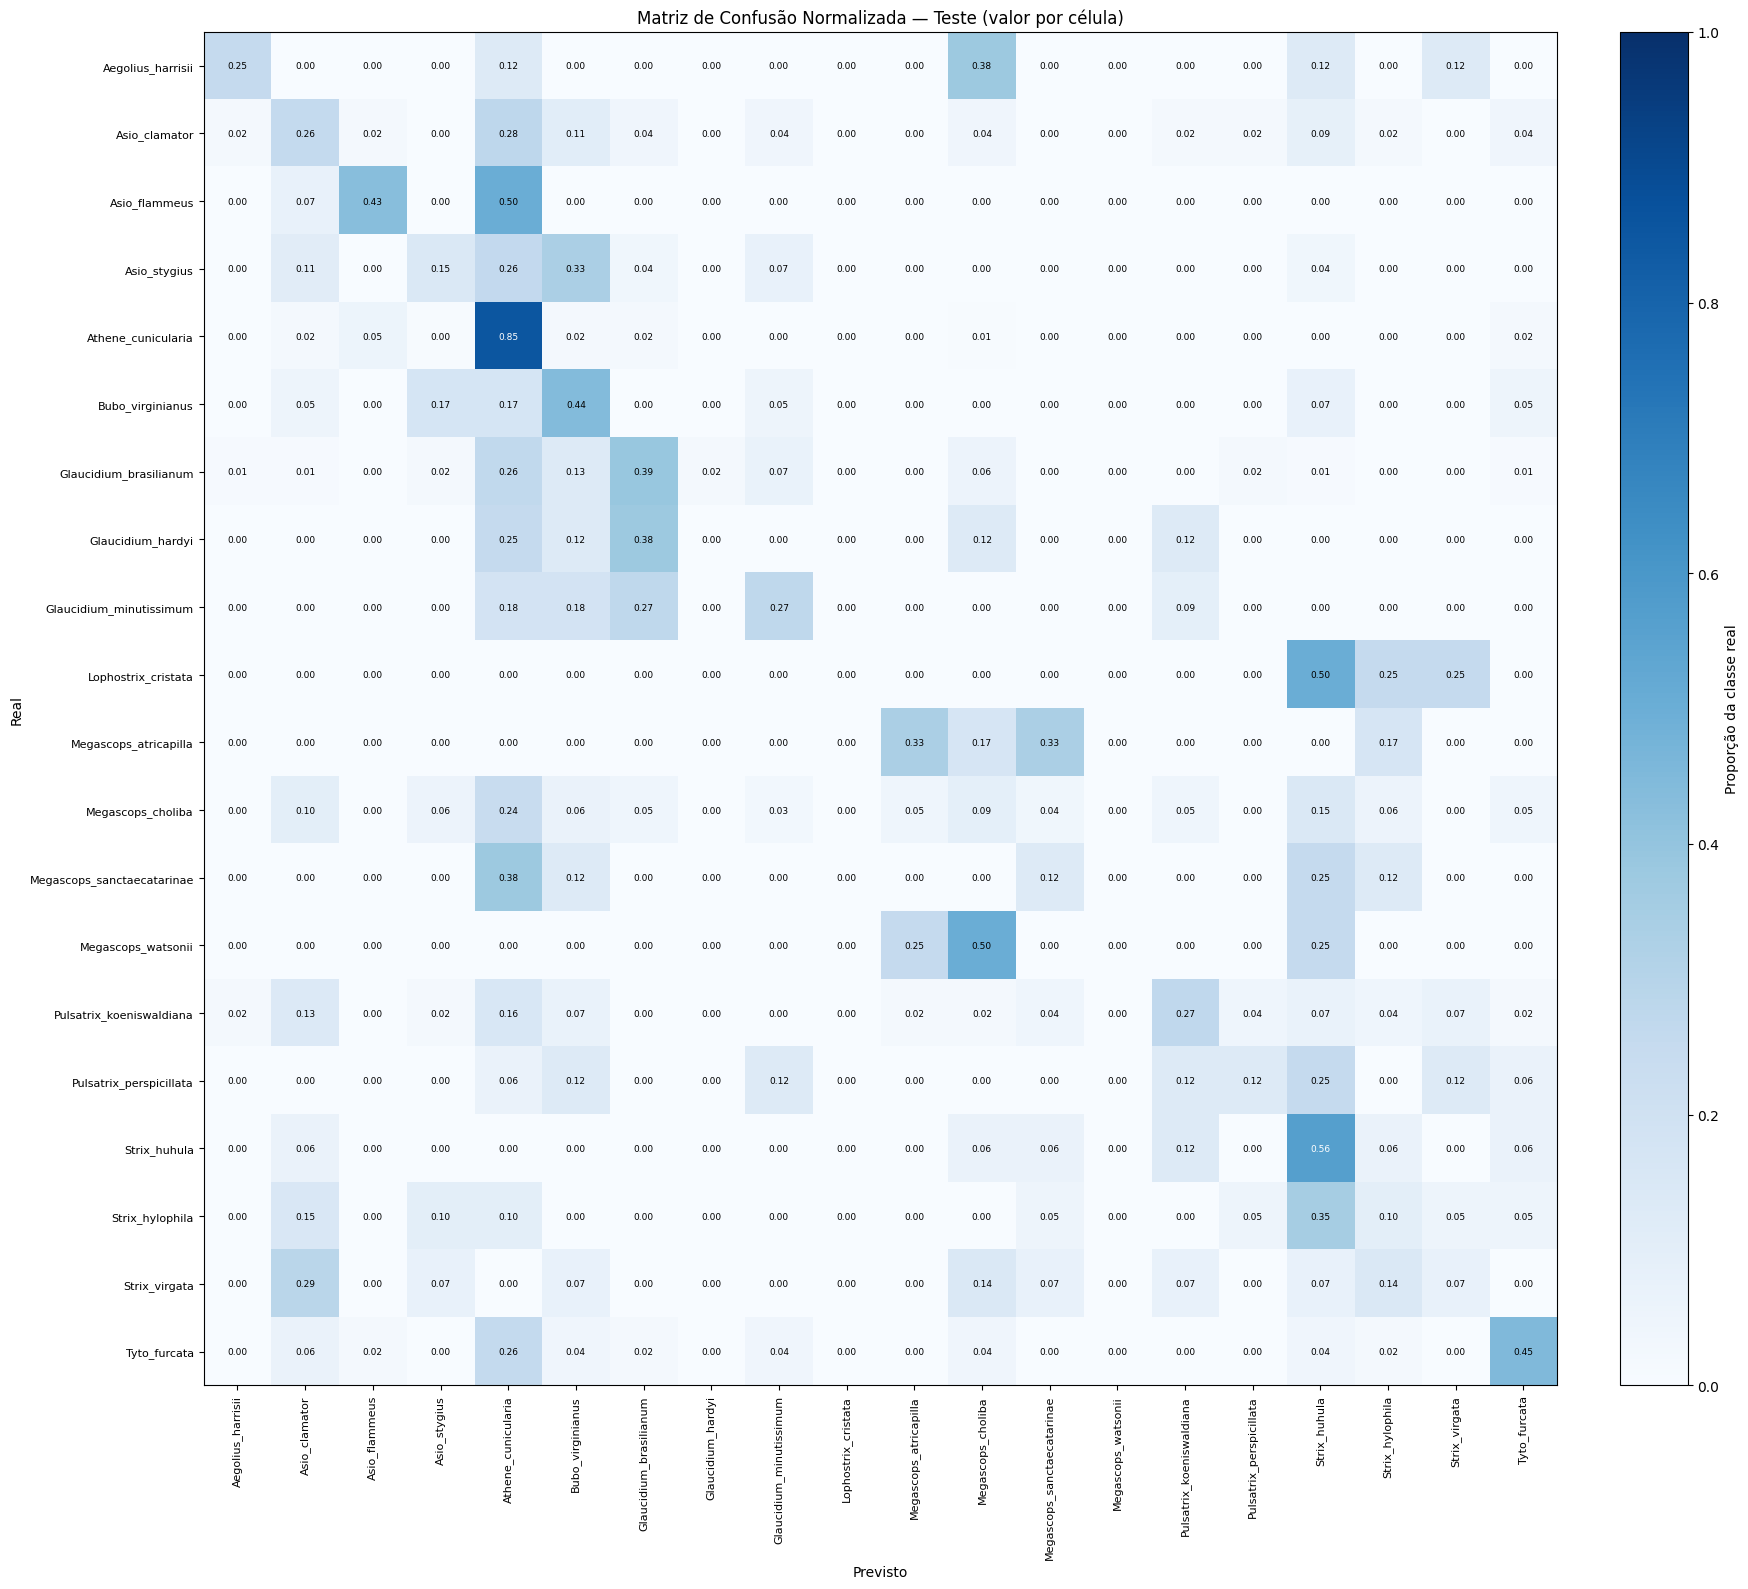

*Figura: matriz de confusão normalizada da V4 no teste. Cada célula representa a proporção de imagens de uma classe real previstas como outra classe.*

# 5. Comparação entre as versões

A V1 é a **versão base**, avaliada em validação 80/20. As versões V2–V5 usam o mesmo teste 70/15/15.

## Métricas de classificação

| Versão | Papel | Acurácia | Acc. balanceada | Precisão macro | Recall macro | F1 macro | Top-3 | Recall zero |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| **V1** | **Base (validação)** | **62,49%** | 10,81% | 10,34% | 10,81% | 9,55% | 77,12% | 14 |
| V2 | Primeira melhoria | 60,03% | 13,38% | 14,13% | 13,38% | 12,66% | — | 12 |
| V3 | Balanceamento agressivo | 31,46% | 20,67% | 12,52% | 20,67% | 11,74% | — | 6 |
| **V4** | **Melhor CNN própria** | **58,63%** | **25,78%** | **23,82%** | **25,78%** | **22,82%** | — | **3** |
| V5 | Busca + ajuste pós-treino | 58,55% | 18,06% | 18,17% | 18,06% | 17,08% | — | 8 |

A V1 usou validação 80/20; as demais usam o mesmo teste 70/15/15. Por isso, a acurácia da V1 não é diretamente comparável com as demais.

## Ficha técnica e custo

| Versão | Parâmetros | Tamanho | Split | Épocas | Tempo de treino | Latência |
|---|---:|---:|---|---:|---:|---:|
| **V1** | 12,94M | ~49,4 MB | 80/20 | 14 | ~121 s | — |
| V2 | 1,21M | 4,62 MB | 70/15/15 | 21 | 2.161 s | — |
| V3 | 1,21M | 4,62 MB | 70/15/15 | 48 | 1.046 s | — |
| **V4** | **1,21M** | **4,62 MB** | **70/15/15** | **50** | **1.931 s** | — |
| V5 | 1,21M | 4,62 MB | 70/15/15 | 35* | 552 s (melhor); 2.410 s total | — |

\* V5: melhor candidato; os três candidatos treinaram 35, 39 e 78 épocas.
A latência não foi medida nos experimentos exportados.

## Pontos fortes e fracos de cada versão

### V1 — base
**Fortes:** arquitetura simples, acurácia global de 62,49% e top-3 de 77,12%.  
**Fracos:** F1 macro de apenas 9,55%, 14 classes com recall zero, 12,94M de parâmetros e nenhum teste separado.  
**Conclusão que levou à V2:** a acurácia global estava escondendo o viés para `Athene`. Era necessário trocar `Flatten` por `GlobalAveragePooling`, separar teste e avaliar métricas macro.

### V2 — primeira melhoria
**Fortes:** acurácia de 60,03%, modelo muito menor (1,21M) e primeiro teste realmente separado.  
**Fracos:** F1 macro de 12,66%, 12 classes com recall zero e baixa precisão macro.  
**Conclusão que levou à V3:** o modelo ainda ignorava as classes raras. Era preciso aumentar o peso delas no treino.

### V3 — balanceamento agressivo
**Fortes:** acurácia balanceada de 20,67%, 6 classes com recall zero e melhora no recall de várias espécies raras.  
**Fracos:** acurácia global de 31,46%, precisão macro de 12,52% e remoção de 2.876 imagens de treino.  
**Conclusão que levou à V4:** o corte de 400 imagens por classe foi agressivo demais. Era melhor manter a base inteira e usar pesos intermediários.

### V4 — melhor CNN própria
**Fortes:** F1 macro de 22,82%, acurácia balanceada de 25,78%, precisão macro de 23,82%, apenas 3 classes com recall zero e acurácia de 58,63%.  
**Fracos:** ainda há 3 classes com recall zero e o F1 macro absoluto é baixo.  
**Conclusão que levou à V5:** tentar buscar automaticamente os pesos e ajustar a fronteira de decisão.

### V5 — busca e ajuste pós-treino
**Fortes:** acurácia de 58,55%, busca automática de pesos e tentativa de calibrar vieses por classe.  
**Fracos:** F1 macro de 17,08%, 8 classes com recall zero e overfitting na validação no ajuste de vieses.  
**Conclusão:** a V5 não superou a V4. O ajuste pós-treino melhorou a validação, mas piorou o teste. A V4 foi mantida como versão final.

## Métricas detalhadas da V1

A V1 não teve conjunto de teste separado. Os números abaixo são do conjunto de **validação 80/20**.

| Métrica | Valor |
|---|---:|
| Loss de validação | 1,3089 |
| Acurácia | **62,49%** |
| Acurácia balanceada | 10,81% |
| Precisão macro | 10,34% |
| Recall macro | 10,81% |
| F1 macro | **9,55%** |
| Top-3 | 77,12% |
| Classes com recall zero | **14** |
| Parâmetros | 12.941.012 |
| Tamanho aproximado | 49,37 MB |

O melhor valor de acurácia observado durante o treino foi **62,86%** na época 14, mas o `EarlyStopping` restaurou os pesos da época 11, que tinham a menor `val_loss` (1,3089). A métrica final do modelo restaurado é 62,49%.


## Versão 5 em detalhe

A V5 testou três configurações de pesos e depois ajustou vieses por classe na validação.

| alpha | w_max | Épocas | Melhor F1 val. | Score | Recall zero | Acurácia val. |
|---:|---:|---:|---:|---:|---:|---:|
| 0,65 | 2,5 | 39 | 16,86% | 0,2941 | 7 | 58,68% |
| 0,75 | 3,0 | 35 | 19,57% | 0,3078 | 7 | 56,94% |
| 0,85 | 3,5 | 78 | 19,79% | 0,2997 | 4 | 53,72% |

O candidato escolhido foi `alpha=0,75`, mas o ajuste de vieses **melhorou a validação e piorou o teste**:

| Métrica no teste | Antes do ajuste | Depois do ajuste |
|---|---:|---:|
| Acurácia | 56,56% | 58,55% |
| Acurácia balanceada | 20,79% | 18,06% |
| F1 macro | 19,20% | 17,08% |
| Recall zero | 5 | 8 |

Isso é um caso de overfitting na validação. O ajuste de 20 vieses em 1.210 imagens de validação não generalizou para o teste.


## Por que a acurácia global caiu depois da V2?

Não é estranho. A V2 e a V4 otimizam coisas diferentes.

| Métrica | V2 | V4 | Leitura |
|---|---:|---:|---|
| Acurácia global | **60,03%** | 58,63% | V4 perdeu 1,40 pp |
| Precisão macro | 14,13% | **23,82%** | V4 ganhou 9,69 pp |
| Recall macro | 13,38% | **25,78%** | V4 ganhou 12,40 pp |
| F1 macro | 12,66% | **22,82%** | V4 ganhou 10,16 pp |
| Classes com recall zero | 12 | **3** | V4 ganhou 9 classes |

A V4 **não perdeu precisão no sentido macro**. Ela perdeu 1,4 ponto de acurácia global, mas ganhou quase 10 pontos de precisão macro e mais de 12 pontos de recall macro.

Isso acontece porque a acurácia global é dominada por `Athene_cunicularia`, que representa mais da metade do teste. Quando o modelo começa a prever melhor as classes raras, ele deixa de acertar algumas imagens da classe majoritária. O saldo é:

- um pouco menos de acurácia global;
- muito mais abrangência;
- muito melhor F1 macro.

A V3 exagerou no balanceamento: removeu 2.876 imagens de treino e usou pesos agressivos. O modelo passou a prever classes raras demais, gerando muitos falsos positivos, e a acurácia caiu para 31,46%.

A V5 tentou corrigir isso com busca de pesos e ajuste de vieses, mas o ajuste overfitou a validação: a acurácia subiu, porém o F1 macro e o recall caíram no teste.

A V1 tinha 62,49% de validação, mas foi avaliada em outro protocolo, sem teste e sem métricas macro. Não há evidência de que ela fosse melhor nas classes raras.

**Conclusão:** a V4 é melhor para o objetivo do projeto — reconhecer as 20 espécies — mesmo com 1,4 ponto a menos de acurácia global.


# 6. Por que a V4 foi a melhor

A V4 combinou decisões que se equilibraram:

1. **Base inteira no treino.** A V3 removeu 2.876 imagens, principalmente de `Athene`, e perdeu informação. A V4 usou as 5.646 imagens de treino.
2. **Pesos intermediários.** O expoente 0,75 e o teto 3,0 deram mais peso às classes raras sem chegar aos pesos extremos da V3, que chegaram a 7,69.
3. **Seleção por F1 macro.** O melhor modelo foi escolhido pela métrica que dá o mesmo peso a todas as classes, não pela acurácia global.
4. **Regularização moderada.** O dropout reduzido permitiu que o modelo aprendesse além do patamar de 60% da V2.

O resultado foi:

- acurácia de 58,63%, praticamente igual à V2;
- F1 macro de 22,82%, quase o dobro da V2;
- apenas 3 classes com recall zero, contra 12 na V2;
- precisão macro de 23,82%, contra 14,13% na V2.

A V5 mostrou que ajustar ainda mais os pesos e os vieses não necessariamente melhora a generalização.


# 7. Problemas enfrentados, soluções e limitações

## Problemas e soluções

| Problema | Solução |
|---|---|
| Estrutura do ZIP e pastas especiais | Download e extração robustos, filtro de diretórios e validação das 20 classes |
| Vazamento entre treino e avaliação | Divisão estratificada 70/15/15 e teste isolado |
| `y_previstos` não definido na avaliação | Correção com `argmax` e geração completa das métricas |
| Overfitting na V1 | `GlobalAveragePooling` no lugar de `Flatten`, redução de parâmetros |
| Desbalanceamento extremo | Pesos de classe; V3 mostrou que pesos agressivos demais colapsam a precisão |
| Subajuste da V2 | Redução do dropout e ajuste da seleção para F1 macro |
| Ajuste pós-treino da V5 | Detectado overfitting na validação; V5 foi descartada como versão final |
| Falta de métricas macro na V1 | Avaliação completa implementada posteriormente |

## Por que o modelo ficou relativamente impreciso

- **Desbalanceamento severo:** 4.415 imagens de `Athene` contra 26 de `Megascops_watsonii`.
- **Poucos exemplos por classe rara:** algumas espécies têm menos de 30 imagens no total.
- **Teste pequeno por classe:** classes com 4–16 imagens tornam o recall instável.
- **CNN própria treinada do zero:** sem pesos pré-treinados, a rede precisa aprender todos os filtros com poucos dados.
- **Semelhança visual:** espécies do mesmo gênero são facilmente confundidas.
- **Fundo e contexto:** o modelo pode aprender habitat em vez de características da ave.
- **Ruído de rótulo:** existem imagens duplicadas e casos com discordância de identificação.
- **Domínio:** iNaturalist tem fotos curadas; câmeras de campo têm infravermelho, desfoque e oclusão.
- **Modelo fechado:** ele sempre escolhe uma das 20 espécies, mesmo que a imagem não seja de coruja.

## Limitações da avaliação

- O teste é único e relativamente pequeno.
- Não há validação externa em imagens de campo.
- A escolha dos pesos da V4 foi informada pelos resultados das versões anteriores.
- O ajuste de vieses da V5 mostrou que a validação pode ser overfitada.
- A V1 foi avaliada em validação 80/20, não no mesmo teste das demais.


# 8. Ramo experimental da V2: MobileNetV2 como teto

A MobileNetV2 **não é uma nova versão da CNN própria**. Ela é um ramo experimental derivado da V2, com o mesmo dataset, o mesmo split 70/15/15, o mesmo teste e o mesmo data augmentation. A única mudança é o backbone: em vez da CNN feita à mão, usamos uma MobileNetV2 pré-treinada na ImageNet.

O objetivo desse ramo é responder:

> Quanto o resultado poderia melhorar se usássemos uma arquitetura consolidada e pré-treinada, sem as limitações de uma CNN treinada do zero?

## O que foi mantido da V2

- Mesma base de imagens;
- mesma divisão treino/validação/teste;
- mesmas classes;
- mesmo redimensionamento para 224×224;
- mesmo data augmentation;
- mesma métrica de avaliação: F1 macro.

## O que mudou

- Backbone MobileNetV2 pré-treinado na ImageNet;
- convoluções *depthwise separable*;
- normalização de `[0,255]` para `[-1,1]`;
- treinamento em duas etapas: cabeça congelada e depois fine-tuning;
- 2.283.604 parâmetros.

## Ficha técnica do ramo

| Item | Valor |
|---|---:|
| Parâmetros | 2.283.604 |
| Tamanho aproximado dos pesos | 8,71 MB |
| Pré-treinamento | ImageNet |
| Entrada | 224×224×3 |
| Normalização | `[-1,1]` |
| Épocas | 24 (10 + 14) |
| Tempo de treino | ~235 s |
| Métricas de teste | ver tabela abaixo |

## Resultados no teste

| Métrica | MobileNetV2 |
|---|---:|
| Loss | 0,5635 |
| Acurácia | **82,66%** |
| Acurácia balanceada | **70,43%** |
| Precisão macro | **66,51%** |
| Recall macro | **70,43%** |
| F1 macro | **66,28%** |
| Top-3 | **95,38%** |
| Classes com recall zero | **0** |

A MobileNetV2 foi melhor em todas as métricas principais e não deixou nenhuma classe com recall zero. O menor recall por espécie foi 25,0% (`Megascops_sanctaecatarinae`), e o maior foi 93,8% (`Strix_huhula`).

## Comparação V1, V4 e MobileNetV2

| Métrica | V1* | V4 | MobileNetV2 |
|---|---:|---:|---:|
| Acurácia | 62,49% | 58,63% | **82,66%** |
| Acurácia balanceada | 10,81% | 25,78% | **70,43%** |
| Precisão macro | 10,34% | 23,82% | **66,51%** |
| Recall macro | 10,81% | 25,78% | **70,43%** |
| F1 macro | 9,55% | 22,82% | **66,28%** |
| Top-3 | 77,12% | — | **95,38%** |
| Recall zero | 14 | 3 | **0** |
| Parâmetros | 12,94M | 1,21M | 2,28M |
| Tempo de treino | 121 s | 1.931 s | **235 s** |

\* V1: validação 80/20; V4 e MobileNetV2: teste 70/15/15.

A comparação mostra três patamares:

1. **V1:** tem acurácia global de 62,49%, mas F1 macro de apenas 9,55% e 14 classes com recall zero. É um modelo grande (12,94M) e muito enviesado para `Athene`.
2. **V4:** reduz a acurácia para 58,63%, mas eleva o F1 macro para 22,82%, a acurácia balanceada para 25,78% e reduz o recall zero para 3 classes. É a melhor CNN própria.
3. **MobileNetV2:** sobe para 82,66% de acurácia e 66,28% de F1 macro, não deixa nenhuma classe com recall zero e treina em 235 s, contra 1.931 s da V4.

A MobileNetV2 tem mais parâmetros que a V4, mas **8 vezes menos tempo de treino** e um desempenho muito superior. Isso mostra o valor dos pesos pré-treinados: a rede não precisa aprender todos os filtros do zero.

## Comparação estrutural

| Item | CNN própria — V4 | MobileNetV2 |
|---|---|---|
| Parâmetros | 1,21M | 2,28M |
| Pré-treinamento | Não | ImageNet |
| Convoluções | 3×3 padrão | Depthwise separable |
| Entrada | 224×224×3 | 224×224×3 |
| Normalização | `[0,1]` | `[-1,1]` |
| Treinamento | Do zero | Cabeça + fine-tuning |
| Vantagem | Controle total, atende ao requisito | Features pré-treinadas, maior eficiência |
| Limitação | Precisa de mais dados | Depende de transfer learning e ajuste fino |

## Código do ramo MobileNetV2

```python
entradas = layers.Input(shape=(224, 224, 3))
x = layers.RandomFlip('horizontal')(entradas)
x = layers.RandomRotation(0.08, fill_mode='reflect')(x)
x = layers.RandomZoom(0.10, fill_mode='reflect')(x)
x = layers.RandomContrast(0.10)(x)
x = layers.Rescaling(1./127.5, offset=-1.0)(x)

base = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet',
    pooling='avg',
)
base.trainable = False

x = base(x, training=False)
x = layers.Dropout(0.3)(x)
saidas = layers.Dense(20, activation='softmax')(x)

modelo = models.Model(entradas, saidas)
```

## Limitações de uma CNN feita à mão

- Não aproveita features de milhões de imagens da ImageNet.
- Precisa de mais dados para aprender filtros do zero.
- Convoluções padrão são mais caras que depthwise separable.
- É mais sensível à inicialização, à taxa de aprendizado e ao dropout.
- Tende a ter pior generalização em domínios diferentes.
- Exige mais experimentos de arquitetura e regularização.

A V4 mostra que uma CNN própria pode ser funcional e atender ao requisito, mas a MobileNetV2 mostra que o transfer learning eleva o resultado a outro patamar.


In [ ]:
comparacao_v1_v4_mob = pd.DataFrame([
    {'Modelo':'V1 (validação)', 'Acurácia':0.6249, 'Acc. balanceada':0.1081, 'F1 macro':0.0955, 'Recall zero':14},
    {'Modelo':'V4 (teste)', 'Acurácia':0.5863, 'Acc. balanceada':0.2578, 'F1 macro':0.2282, 'Recall zero':3},
    {'Modelo':'MobileNetV2 (teste)', 'Acurácia':0.8266, 'Acc. balanceada':0.7043, 'F1 macro':0.6628, 'Recall zero':0},
])

display(comparacao_v1_v4_mob.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

comparacao_v1_v4_mob.set_index('Modelo')[['Acurácia','Acc. balanceada','F1 macro']].plot(
    kind='bar', ax=axes[0], rot=0,
    color=['#4C78A8','#F58518','#54A24B']
)
axes[0].set_title('V1 vs V4 vs MobileNetV2')
axes[0].set_ylim(0, 1)
axes[0].grid(axis='y', alpha=0.3)
axes[0].legend(fontsize=8)

comparacao_v1_v4_mob.set_index('Modelo')['Recall zero'].plot(
    kind='bar', ax=axes[1], rot=0, color='#B279A2'
)
axes[1].set_title('Classes com recall zero')
axes[1].set_ylabel('Quantidade')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
params = pd.Series({
    'V1 — CNN com Flatten': 12.94,
    'V2–V5 — CNN com GAP': 1.21,
    'MobileNetV2': 2.28,
})

params.plot.bar(figsize=(8, 5), color=['#B279A2', '#4C78A8', '#54A24B'], rot=0)
plt.title('Parâmetros por arquitetura')
plt.ylabel('Milhões de parâmetros')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

display(params.rename('Parâmetros (milhões)').to_frame())


# 9. Conclusão e aplicações em Engenharia

## Conclusão

A **V4** foi a melhor versão oficial da CNN própria:

- **58,63%** de acurácia no teste;
- **22,82%** de F1 macro;
- **25,78%** de acurácia balanceada;
- apenas **3 classes com recall zero**.

A V2 tinha acurácia ligeiramente maior, mas F1 macro de apenas 12,66% e 12 classes com recall zero. Para um problema desbalanceado, a V4 é claramente melhor.

A **MobileNetV2**, usada como ramo experimental da V2, foi muito superior:

- **82,66%** de acurácia;
- **66,28%** de F1 macro;
- **70,43%** de acurácia balanceada;
- **0 classes com recall zero**.

Ela treinou em cerca de **235 s**, contra **1.931 s** da V4. Isso mostra que o transfer learning resolve parte do problema que a CNN feita à mão não consegue resolver com os dados disponíveis.

O projeto mostrou que:

1. a arquitetura importa, mas **qualidade e distribuição dos dados importam mais**;
2. balanceamento agressivo pode piorar a precisão;
3. pesos intermediários com a base inteira foram o melhor compromisso para a CNN própria;
4. ajustes pós-treino podem overfitar a validação;
5. uma CNN própria é viável como prova de conceito, mas o transfer learning é o caminho para melhorar o desempenho.

## Aplicações práticas

- Monitoramento não intrusivo de corujas em reservas e parques.
- Apoio à catalogação de avifauna por pesquisadores.
- Pré-triagem de imagens de câmeras trap.
- Base para um sistema embarcado com câmera e modelo quantizado.
